# Mission 4 — Waypoint navigation #1: data analytics

Loads the mission's data from `../data` into pandas, and finds when the autopilot drove the
boat towards each of the three destinations.

- `../data/mqtt/*.jsonl` — everything on the boat's MQTT topics, as written by the MQTT logger
  (software/mqtt_logger): telemetry once a second and the commands sent to the boat.
- `../data/ref_gps_track/*.kml` — a reference track recorded by a phone (BasicAirData GPS
  Logger) carried with the boat.

Times are UTC. Positions are not displayed; where they are needed they are compared as
distances in metres.

In [1]:
import json
import math
import re
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("../data")

# The phone names its track after its local start time and writes no time per point. Its
# clock was on Central Daylight Time, and it logs one point a second (1075 points over the
# 17:54 the track says it lasted); the check further down confirms both against the boat's GPS.
REF_TRACK_UTC_OFFSET = timezone(timedelta(hours=-5))
REF_TRACK_INTERVAL_S = 1.0

EARTH_RADIUS_M = 6371000


def utc(unix):
    """Unix seconds -> pandas UTC timestamp."""
    return pd.to_datetime(unix, unit="s", utc=True)


def hms(ts):
    return "" if pd.isna(ts) else ts.strftime("%H:%M:%S")


def distance_m(lat1, lon1, lat2, lon2):
    """Metres between points, equirectangular (as in missions 2 and 3); fine over a few km."""
    x = np.radians(lon2 - lon1) * np.cos(np.radians(lat1)) * EARTH_RADIUS_M
    y = np.radians(lat2 - lat1) * EARTH_RADIUS_M
    return np.hypot(x, y)

## MQTT log

`messages` has one row per MQTT message. `tel` is the boat's telemetry flattened into columns
(`gps.lat_e7`, `output.reason`, `bcu.esp32_mode`, ...), and `commands` the commands sent to it.
`bcu.*` is empty in the seconds when the Body Control Unit's status read failed its checksum, so
`autonomous` carries the last known switch position forward.

In [2]:
mqtt_files = sorted((DATA_DIR / "mqtt").glob("*.jsonl"))
messages = pd.DataFrame([json.loads(line) for f in mqtt_files for line in open(f)])
messages["time"] = utc(messages.unix)

tel = pd.json_normalize([dict(unix=m.unix, **m.data) for m in messages.itertuples() if m.topic.endswith("/telemetry")])
tel["time"] = utc(tel.unix)
tel["autonomous"] = tel["bcu.esp32_mode"].astype("boolean").ffill()
tel["lat"] = tel["gps.lat_e7"] / 1e7
tel["lon"] = tel["gps.lon_e7"] / 1e7

commands = pd.json_normalize([dict(unix=m.unix, **m.data) for m in messages.itertuples() if m.topic.endswith("/cmd")])
commands["time"] = utc(commands.unix)

print("files:", [f.name for f in mqtt_files])
print("%d messages: %d telemetry, %d commands, from %s to %s UTC" % (
    len(messages), len(tel), len(commands), hms(messages.time.min()), hms(messages.time.max())))
print("telemetry sequence numbers: %d to %d, %d missing" % (
    tel.seq.min(), tel.seq.max(), tel.seq.max() - tel.seq.min() + 1 - tel.seq.nunique()))
commands[["time", "cmd"]].assign(time=commands.time.map(hms))

files: ['mqtt_20261017T2240Z.jsonl', 'mqtt_20261017T2250Z.jsonl', 'mqtt_20261017T2300Z.jsonl']
1249 messages: 1246 telemetry, 3 commands, from 22:48:54 to 23:09:35 UTC
telemetry sequence numbers: 1 to 1246, 0 missing


,time,cmd
0,23:01:40,destination
1,23:03:48,destination
2,23:04:59,destination


## Reference GPS track

The KML holds one line of `lon,lat,altitude` points. Each point's time is reconstructed from the
track's start time in its name and one point a second.

In [3]:
kml_path = sorted((DATA_DIR / "ref_gps_track").glob("*.kml"))[0]
kml = kml_path.read_text()
points = [tuple(map(float, p.split(","))) for p in re.search(r"<coordinates>(.*?)</coordinates>", kml, re.S).group(1).split()]
ref = pd.DataFrame(points, columns=["lon", "lat", "alt_m"])

stamp = re.search(r"<name>GPS Logger (\d{8}-\d{6})</name>", kml).group(1)
ref_start = datetime.strptime(stamp, "%Y%m%d-%H%M%S").replace(tzinfo=REF_TRACK_UTC_OFFSET)
ref["unix"] = ref_start.timestamp() + ref.index * REF_TRACK_INTERVAL_S
ref["time"] = utc(ref.unix)
summary = re.search(r"Distance = ([^<]+)<br>Duration = ([^<]+)<br>", kml)
print("%s: %d points, %s to %s UTC (the logger reports: distance %s, duration %s)" % (
    kml_path.name, len(ref), hms(ref.time.iloc[0]), hms(ref.time.iloc[-1]), summary.group(1), summary.group(2).split(" | ")[0]))

20261017-175204.kml: 1075 points, 22:52:04 to 23:09:58 UTC (the logger reports: distance 513 m, duration 17:54)


**Timing check.** If the reconstructed times are right, the phone and the boat were in the same
place at the same moment. Shifting the phone's times by a few seconds either way should only make
the two tracks drift apart. The smallest distance should be at a shift of 0, or within a second or two of it (the
phone's and the boat's fixes are each about a second apart).

In [4]:
fixes = tel[tel["gps.fix_valid"].astype(bool)]


def median_gap_m(shift_s):
    ref_at = ref.set_index("unix")[["lat", "lon"]]
    nearest = np.searchsorted(ref_at.index.to_numpy(), fixes.unix.to_numpy() - shift_s)
    ok = (nearest > 0) & (nearest < len(ref_at))
    r = ref_at.iloc[nearest[ok]]
    return float(np.median(distance_m(fixes.lat.to_numpy()[ok], fixes.lon.to_numpy()[ok], r.lat.to_numpy(), r.lon.to_numpy())))


alignment = pd.Series({shift: round(median_gap_m(shift), 1) for shift in (-60, -30, -10, -5, -2, 0, 2, 5, 10, 30, 60)},
                      name="median distance, boat to phone (m)")
alignment.index.name = "phone time shifted by (s)"
alignment.to_frame().T

phone time shifted by (s),-60,-30,-10,-5,-2,0,2,5,10,30,60
"median distance, boat to phone (m)",29.3,16.5,6.8,3.9,3.2,2.7,2.6,3.2,5.0,15.1,29.0


## The three autopilot runs

For each destination sent:

| Column | What it is |
|---|---|
| sent | When the command was published |
| started | First telemetry message where the boat had the destination and was navigating towards it |
| arrived | First time the boat reported being inside its arrival radius |
| ended | The first of: arrival, the next destination, or the RC switch going off autonomous |

The Body Control Unit only drives the motor while the switch is on autonomous, so *autonomous at
start* says whether that run actually moved the boat.

In [5]:
runs = []
cmd_dest = commands[commands.cmd == "destination"].reset_index(drop=True)
for i, c in cmd_dest.iterrows():
    next_sent = cmd_dest.unix.iloc[i + 1] if i + 1 < len(cmd_dest) else np.inf
    mine = tel[(tel.unix >= c.unix) & (tel.unix < next_sent)
               & (tel["destination.lat_e7"] == c.lat_e7) & (tel["destination.lon_e7"] == c.lon_e7)]
    nav = mine[mine["output.reason"] == "navigating"]
    started = nav.unix.iloc[0] if len(nav) else np.nan
    after = mine[mine.unix >= started] if len(nav) else mine.iloc[0:0]
    arrived = after.loc[after["nav.state"] == "arrived", "unix"].min()
    to_rc = after.loc[after.autonomous == False, "unix"].min()  # noqa: E712 (pandas boolean with NA)
    ends = {"arrived": arrived, "next destination": next_sent, "switched to RC": to_rc}
    ended_by = min((v, k) for k, v in ends.items() if pd.notna(v) and v < np.inf)[1] if len(nav) else ""
    ended = ends.get(ended_by, np.nan)
    first = after.iloc[0] if len(after) else None
    at_arrival = after[after.unix == arrived]
    runs.append({
        "destination": i + 1,
        "sent": utc(c.unix),
        "started": utc(started),
        "arrived": utc(arrived),
        "ended": utc(ended),
        "ended by": ended_by,
        "duration (s)": round(ended - started) if pd.notna(started) and pd.notna(ended) else np.nan,
        "autonomous at start": None if first is None else bool(first.autonomous),
        "distance at start (m)": None if first is None else first["nav.distance_m"],
        "distance at arrival (m)": at_arrival["nav.distance_m"].iloc[0] if len(at_arrival) else np.nan,
        "_start_unix": started, "_end_unix": ended,
    })
runs = pd.DataFrame(runs).set_index("destination")

shown = runs.drop(columns=["_start_unix", "_end_unix"]).copy()
for col in ("sent", "started", "arrived", "ended"):
    shown[col] = shown[col].map(hms)
shown

,sent,started,arrived,ended,ended by,duration (s),autonomous at start,distance at start (m),distance at arrival (m)
destination,,,,,,,,,
1,23:01:40,23:01:43,23:03:29,23:03:29,arrived,106,True,53.0,4.0
2,23:03:48,23:03:51,23:04:44,23:04:44,arrived,53,True,44.8,3.6
3,23:04:59,23:05:01,23:06:45,23:06:45,arrived,104,True,65.6,3.7


In [6]:
# Telemetry of each run, for the analysis that follows: run_tel[1], run_tel[2], run_tel[3].
run_tel = {n: tel[(tel.unix >= r._start_unix) & (tel.unix <= r._end_unix)] for n, r in runs.iterrows()}
ref_run = {n: ref[(ref.unix >= r._start_unix) & (ref.unix <= r._end_unix)] for n, r in runs.iterrows()}
for n in runs.index:
    print("run %d: %d telemetry messages, %d reference points" % (n, len(run_tel[n]), len(ref_run[n])))

# After the last arrival the boat kept its destination; worth knowing before reading the end of the log.
last = runs.iloc[-1]
later = tel[(tel.unix > last._end_unix) & (tel["output.reason"] == "navigating")]
if len(later):
    print("after run %d: 'navigating' again from %s UTC for %d messages, autonomous: %s" % (
        runs.index[-1], hms(later.time.iloc[0]), len(later), sorted(later.autonomous.dropna().unique().tolist())))

run 1: 107 telemetry messages, 106 reference points
run 2: 54 telemetry messages, 53 reference points
run 3: 105 telemetry messages, 104 reference points
after run 3: 'navigating' again from 23:07:54 UTC for 103 messages, autonomous: [False]


## Tracks during the autonomous runs

The boat's own GNSS (as it reported it in telemetry) and the phone's reference track, for the three
runs only. Each destination is drawn with its arrival radius.

The axes are metres east and north of the boat's first fix in run 1, which keeps the coordinates
out of the notebook. Set `SHOW_COORDINATES = True` to plot in degrees instead.

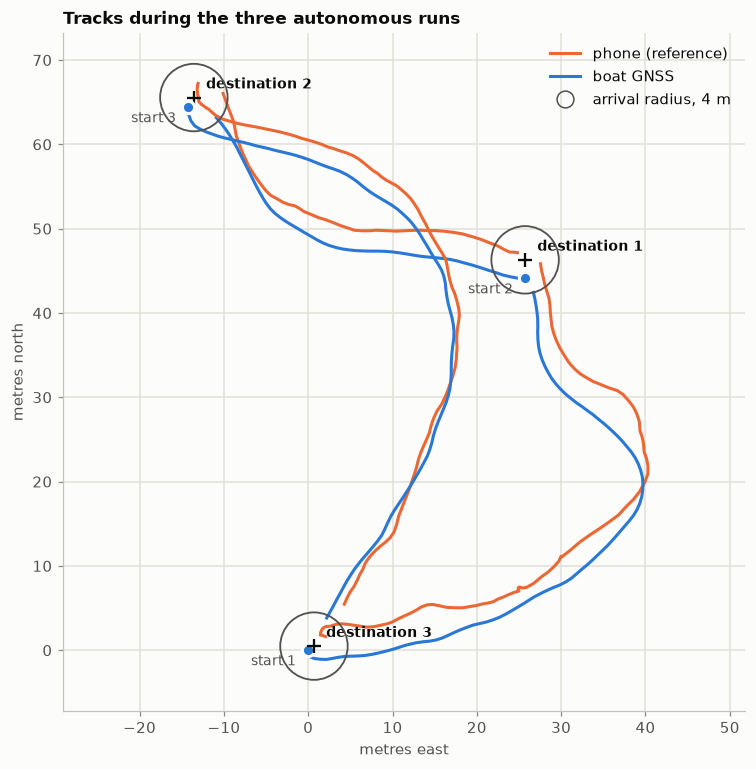

,"boat to phone, median (m)","boat to phone, 95 % (m)","boat to phone, max (m)"
run,,,
1,4.0,6.1,6.3
2,3.5,4.2,4.4
3,1.4,2.8,3.1


In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

SHOW_COORDINATES = False
ARRIVAL_RADIUS_M = 4  # the boat's gnc.py

BOAT, PHONE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 (colour-blind checked)
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110,
})

origin = run_tel[runs.index[0]].query("`gps.fix_valid`").iloc[0]


def xy(lat, lon):
    """Plot coordinates: degrees, or metres east / north of the origin (equirectangular)."""
    lat, lon = np.asarray(lat, dtype=float), np.asarray(lon, dtype=float)
    if SHOW_COORDINATES:
        return lon, lat
    east = np.radians(lon - origin.lon) * np.cos(np.radians(origin.lat)) * EARTH_RADIUS_M
    north = np.radians(lat - origin.lat) * EARTH_RADIUS_M
    return east, north


fig, ax = plt.subplots(figsize=(8, 8))
for n in runs.index:
    boat = run_tel[n].query("`gps.fix_valid`")
    ax.plot(*xy(ref_run[n].lat, ref_run[n].lon), color=PHONE, lw=2, label="phone (reference)" if n == runs.index[0] else None)
    ax.plot(*xy(boat.lat, boat.lon), color=BOAT, lw=2, label="boat GNSS" if n == runs.index[0] else None)
    sx, sy = xy([boat.lat.iloc[0]], [boat.lon.iloc[0]])
    ax.plot(sx, sy, "o", color=BOAT, ms=8, mec=SURFACE, mew=2, zorder=5)
    ax.annotate("start %d" % n, (sx[0], sy[0]), xytext=(-8, -3), textcoords="offset points", ha="right", va="top", color=INK_2, fontsize=9)

    dest = cmd_dest.iloc[n - 1]
    dx, dy = xy([dest.lat_e7 / 1e7], [dest.lon_e7 / 1e7])
    if SHOW_COORDINATES:  # the radius in degrees, roughly
        rx = ARRIVAL_RADIUS_M / (EARTH_RADIUS_M * math.cos(math.radians(dest.lat_e7 / 1e7))) * 180 / math.pi
    else:
        rx = ARRIVAL_RADIUS_M
    ax.add_patch(Circle((dx[0], dy[0]), rx, fill=False, color=INK_2, lw=1.2, zorder=4))
    ax.plot(dx, dy, "+", color=INK, ms=9, mew=1.5, zorder=5)
    ax.annotate("destination %d" % n, (dx[0], dy[0]), xytext=(8, 6), textcoords="offset points", color=INK, fontsize=9, fontweight="bold")

ax.set_aspect("equal", adjustable="datalim")
ax.set_xlabel("longitude (°)" if SHOW_COORDINATES else "metres east")
ax.set_ylabel("latitude (°)" if SHOW_COORDINATES else "metres north")
ax.set_title("Tracks during the three autonomous runs")
handles, labels = ax.get_legend_handles_labels()
handles.append(plt.Line2D([], [], color=INK_2, lw=1.2, marker="o", ms=11, mfc="none", ls="none"))
labels.append("arrival radius, %d m" % ARRIVAL_RADIUS_M)
ax.legend(handles, labels, loc="best")
plt.show()

# How far apart the two tracks were at the same moment, per run.
gaps = {}
for n in runs.index:
    boat = run_tel[n].query("`gps.fix_valid`")
    idx = np.clip(np.searchsorted(ref.unix.to_numpy(), boat.unix.to_numpy()), 0, len(ref) - 1)
    d = distance_m(boat.lat.to_numpy(), boat.lon.to_numpy(), ref.lat.to_numpy()[idx], ref.lon.to_numpy()[idx])
    gaps[n] = {"median (m)": round(float(np.median(d)), 1), "95 % (m)": round(float(np.quantile(d, 0.95)), 1), "max (m)": round(float(d.max()), 1)}
pd.DataFrame(gaps).T.rename_axis("run").rename(columns=lambda c: "boat to phone, " + c)

Observations:
- on-board and reference GPS readings do have an offset showing onboard module readings generally pointing 4 meters to the south comparing to the reference smarphone sensors
- with that, the progression and heading appear to be relatively similar between the two, which gives the general confidence in GPS sensor
- practically, the UAV did reach its destinations
- the straight line navigation path has the obvious curavature which will require further research
- given the confirmed general reliability of GPS readings, the compass accuracy or rudder performance are to be investigated

Note: navigation was done on the Oct 17 version of the firmware without implementation of fixes for issues listed in Mission 3.

## Checking the observations above

The first observation, in numbers: where the boat's GNSS put the boat relative to the phone, at
the same moments, during the runs. Positive east / north means the boat's fix was east / north of
the phone's.

In [8]:
offsets = []
for n in runs.index:
    boat = run_tel[n].query("`gps.fix_valid`")
    idx = np.clip(np.searchsorted(ref.unix.to_numpy(), boat.unix.to_numpy()), 0, len(ref) - 1)
    lat_p, lon_p = ref.lat.to_numpy()[idx], ref.lon.to_numpy()[idx]
    east = np.radians(boat.lon.to_numpy() - lon_p) * np.cos(np.radians(lat_p)) * EARTH_RADIUS_M
    north = np.radians(boat.lat.to_numpy() - lat_p) * EARTH_RADIUS_M
    offsets.append({"run": n, "east (m), median": round(float(np.median(east)), 1), "north (m), median": round(float(np.median(north)), 1),
                    "distance (m), median": round(float(np.median(np.hypot(east, north))), 1)})
pd.DataFrame(offsets).set_index("run")

,"east (m), median","north (m), median","distance (m), median"
run,,,
1,-1.5,-2.9,4.0
2,1.5,-3.1,3.5
3,-0.9,-1.2,1.4


## Compass test: compass heading against the course over ground

**The idea:** the boat only moves bow first, so the direction it travels (its course over ground,
from GPS) should be the direction it points (its heading, from the compass). The difference
between the two is the compass error.

**It holds, with five conditions:**

1. **The course has to be measurable.** At walking pace a GNSS course is noisy, and it is
   meaningless when the boat barely moves. Only samples where the boat makes headway count.
2. **Only fairly straight travel counts.** In a turn the bow swings first and the track follows,
   so heading and course disagree for reasons that have nothing to do with the compass.
3. **Wind and current push the boat sideways** (leeway), so even on a straight line the course can
   differ from the heading by a few degrees. On a small, slow boat that cannot be ruled out, and it
   would look like compass error. Nothing in this data measures it.
4. **The compass reads magnetic north; GPS courses are true north.** The difference is the local
   magnetic declination, a few degrees, which has to be taken off before calling anything an
   error. Set `MAGNETIC_DECLINATION_DEG` (east positive) below; with 0 it is included in the error.
5. **A compass error is rarely one number.** Iron and currents near the sensor (motor, battery,
   wiring) bend the field differently depending on which way the boat points. So the error has to
   be looked at against the heading, not just averaged.

**A finding before the test even starts:** the course the GNSS module reports itself (`gps.cog_deg`)
cannot be used. It sits at the same value for minutes on end while the boat is moving; the
receiver appears to freeze its course at this low speed. So the course here is worked out from
positions instead: the direction from where the boat was 2 seconds before to where it was 2
seconds after. The same is done with the phone's track, as a cross-check.

In [9]:
MAGNETIC_DECLINATION_DEG = 0.0  # east positive; look it up for the test site (e.g. NOAA's calculator)
BASELINE_S = 4  # course from the positions this many seconds apart, centred on the sample
MIN_SPEED_M_S = 0.5  # slower than this, the course isn't trusted
MAX_TURN_DEG_S = 5  # turning faster than this, heading and course legitimately differ


def wrap180(a):
    return (np.asarray(a, dtype=float) + 180) % 360 - 180


def course_from_positions(unix, lat, lon, at):
    """Course (degrees true) and speed (m/s) at times `at`, from positions BASELINE_S apart."""
    unix, lat, lon = (np.asarray(v, dtype=float) for v in (unix, lat, lon))
    la0, lo0 = np.interp(at - BASELINE_S / 2, unix, lat), np.interp(at - BASELINE_S / 2, unix, lon)
    la1, lo1 = np.interp(at + BASELINE_S / 2, unix, lat), np.interp(at + BASELINE_S / 2, unix, lon)
    east = np.radians(lo1 - lo0) * np.cos(np.radians(la0)) * EARTH_RADIUS_M
    north = np.radians(la1 - la0) * EARTH_RADIUS_M
    return np.degrees(np.arctan2(east, north)) % 360, np.hypot(east, north) / BASELINE_S


stuck = tel["gps.cog_deg"].round(1).value_counts()
print("the module's own course: %d distinct values in %d messages; the most common, %.1f°, in %d of them" % (
    tel["gps.cog_deg"].nunique(), len(tel), stuck.index[0], stuck.iloc[0]))

samples = []
for n in runs.index:
    boat = run_tel[n].query("`gps.fix_valid`")
    t = boat.unix.to_numpy()
    inner = (t >= t[0] + BASELINE_S / 2) & (t <= t[-1] - BASELINE_S / 2)
    course, speed = course_from_positions(t, boat.lat, boat.lon, t[inner])
    phone_course, _ = course_from_positions(ref.unix, ref.lat, ref.lon, t[inner])
    samples.append(pd.DataFrame({
        "run": n, "unix": t[inner], "s": t[inner] - t[0],
        "heading": boat["compass.heading"].to_numpy()[inner], "accuracy": boat["compass.accuracy"].to_numpy()[inner],
        "course": course, "phone_course": phone_course, "speed": speed}))
cmp = pd.concat(samples, ignore_index=True)
cmp["turn_deg_s"] = cmp.groupby("run").course.transform(lambda c: pd.Series(wrap180(np.diff(c, prepend=c.iloc[0])), index=c.index).abs())
cmp["error"] = wrap180(cmp.heading + MAGNETIC_DECLINATION_DEG - cmp.course)
cmp["usable"] = (cmp.speed >= MIN_SPEED_M_S) & (cmp.turn_deg_s <= MAX_TURN_DEG_S)

print("course from the boat's positions vs from the phone's: median difference %+.1f°, half of them within %.1f°" % (
    np.median(wrap180(cmp.course - cmp.phone_course)), np.median(np.abs(wrap180(cmp.course - cmp.phone_course)))))
print("usable samples: %d of %d (moving at %.1f m/s or more, turning %d°/s or less)" % (cmp.usable.sum(), len(cmp), MIN_SPEED_M_S, MAX_TURN_DEG_S))
u = cmp[cmp.usable]
summary = u.groupby("run").agg(samples=("error", "size"), course_from=("course", "min"), course_to=("course", "max"),
                               error_median=("error", "median"),
                               error_p25=("error", lambda e: e.quantile(0.25)), error_p75=("error", lambda e: e.quantile(0.75)))
summary.loc["all"] = [len(u), u.course.min(), u.course.max(), u.error.median(), u.error.quantile(0.25), u.error.quantile(0.75)]
summary.round(1).rename(columns={"course_from": "course from (°)", "course_to": "course to (°)", "error_median": "compass error, median (°)",
                                 "error_p25": "25 % (°)", "error_p75": "75 % (°)"})

the module's own course: 94 distinct values in 1246 messages; the most common, 177.6°, in 741 of them
course from the boat's positions vs from the phone's: median difference -1.4°, half of them within 5.3°
usable samples: 215 of 252 (moving at 0.5 m/s or more, turning 5°/s or less)


,samples,course from (°),course to (°),"compass error, median (°)",25 % (°),75 % (°)
run,,,,,,
1,78.0,28.1,358.2,-67.0,-72.4,-8.8
2,45.0,271.5,333.3,7.8,-0.7,19.2
3,92.0,103.5,220.0,19.2,-5.7,51.0
all,215.0,28.1,358.2,1.2,-21.1,20.3


**Heading and course over time.** Where the two lines run together, the compass agrees with the
direction of travel. A steady gap is a compass offset at that heading; the shaded stretches are
turns or slow moments, left out of the numbers.

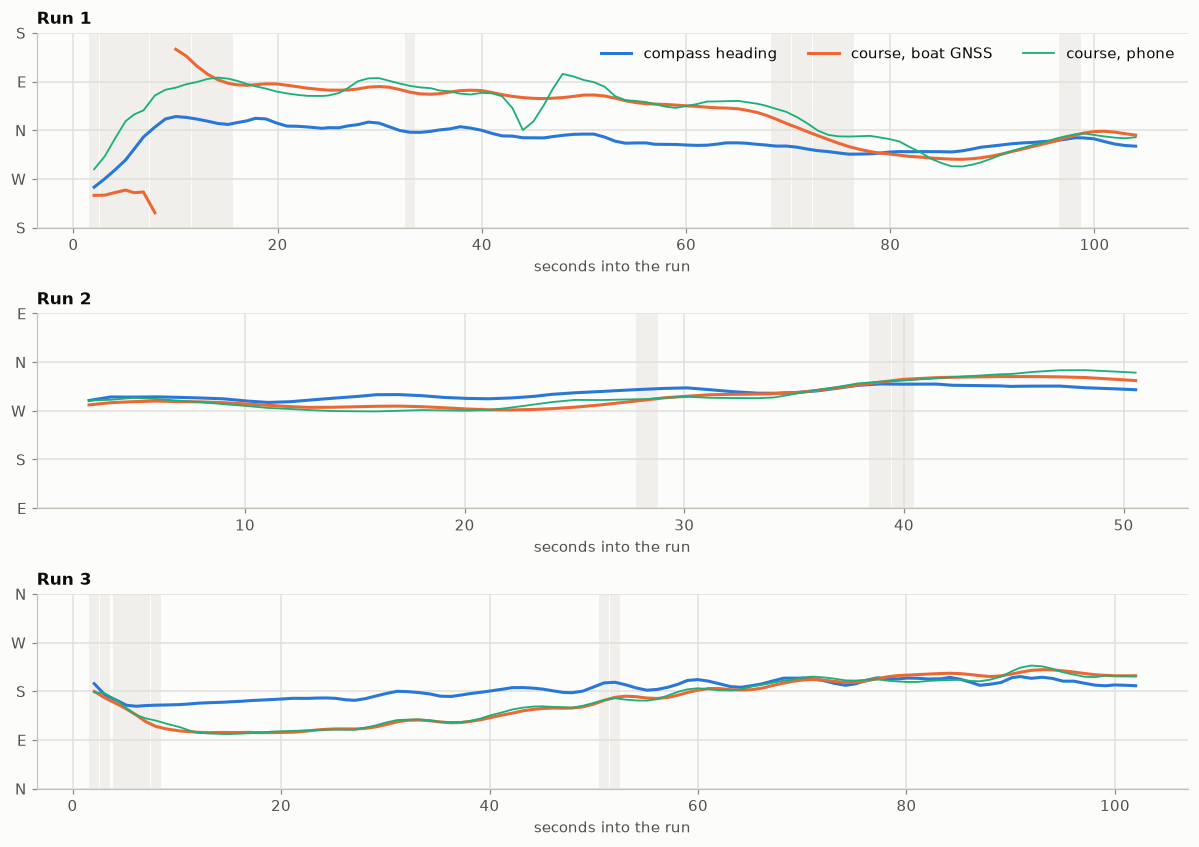

In [10]:
SERIES = {"heading": ("compass heading", BOAT), "course": ("course, boat GNSS", PHONE), "phone_course": ("course, phone", "#1baf7a")}
CARDINAL = {0: "N", 90: "E", 180: "S", 270: "W"}

fig, axes = plt.subplots(len(runs), 1, figsize=(11, 2.6 * len(runs)))
for ax, n in zip(np.atleast_1d(axes), runs.index):
    r = cmp[cmp.run == n]
    # Centre each panel on the run's general direction (to the nearest N / E / S / W), so a run
    # heading north doesn't jump between the top and the bottom of the chart at 0 / 360.
    mean = np.degrees(np.arctan2(np.sin(np.radians(r.course)).mean(), np.cos(np.radians(r.course)).mean()))
    centre = (round(mean / 90) * 90) % 360
    for s_, ok in zip(r.s, r.usable):
        if not ok:
            ax.axvspan(s_ - 0.5, s_ + 0.5, color="#f0efec", lw=0, zorder=0)
    for col, (label, color) in SERIES.items():
        y = centre + wrap180(r[col] - centre)
        y[np.abs(np.diff(y, prepend=y[0])) > 180] = np.nan  # break the line where it wraps past the top / bottom
        ax.plot(r.s, y, color=color, lw=1.2 if col == "phone_course" else 2, label=label)
    ticks = np.arange(centre - 180, centre + 181, 90)
    ax.set_yticks(ticks, [CARDINAL[int(t) % 360] for t in ticks])
    ax.set_ylim(centre - 180, centre + 180)
    ax.set_title("Run %d" % n)
    ax.set_xlabel("seconds into the run")
axes[0].legend(loc="upper right", ncol=3)
fig.tight_layout()
plt.show()

**Compass heading against the direction of travel.** A perfect compass puts every point on the
diagonal. A compass rotated on its mount shifts the points up or down by a constant. Iron near the
sensor bends the line into a wave that repeats once per full turn, and a deviation curve can
correct that. Points that run *flat*, the compass barely moving while the boat's direction changes,
mean the compass is not following the boat at all.

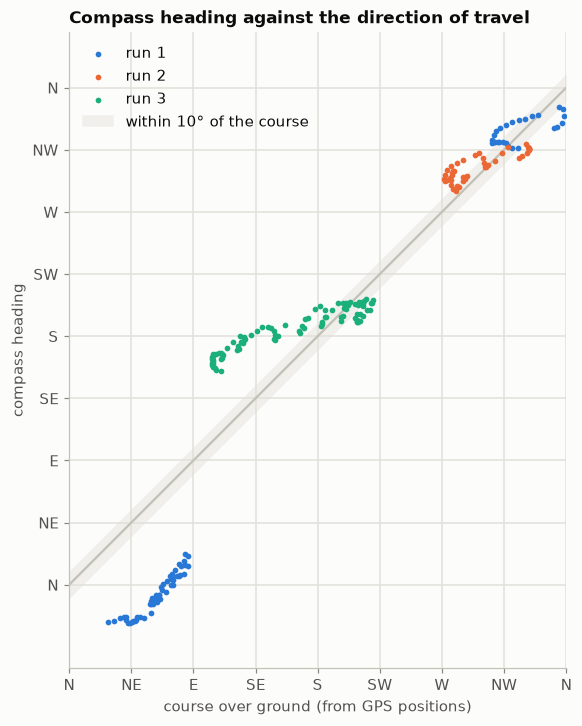

compass error spread: 43° rms around a single offset, 19° rms around the best deviation curve
share of usable samples within 10° of the course: 24 %
run 1: the compass turned 1.27° per degree the boat's course turned (1.00 = follows it)
run 2: the compass turned 0.38° per degree the boat's course turned (1.00 = follows it)
run 3: the compass turned 0.34° per degree the boat's course turned (1.00 = follows it)
compass calibration accuracy during them (0-3): {2: 92, 3: 123}


In [11]:
RUN_COLORS = {1: "#2a78d6", 2: "#eb6834", 3: "#1baf7a"}

fig, ax = plt.subplots(figsize=(7.5, 7.5))
ax.fill_between([0, 360], [-10, 350], [10, 370], color="#f0efec", lw=0, zorder=0)
ax.plot([0, 360], [0, 360], color=AXIS, lw=1.5, zorder=1)
for n in runs.index:
    r = u[u.run == n]
    # draw headings next to the diagonal: a reading of 355 for a course of 10 belongs at -5, not 355
    shown = r.course + wrap180(r.heading - r.course)
    ax.scatter(r.course, shown, s=14, color=RUN_COLORS[n], linewidths=0, label="run %d" % n, zorder=3)
ticks = [0, 45, 90, 135, 180, 225, 270, 315, 360]
names = ["N", "NE", "E", "SE", "S", "SW", "W", "NW", "N"]
ax.set_xticks(ticks, names)
ax.set_yticks(ticks, names)
ax.set_xlim(0, 360)
ax.set_ylim(-60, 400)
ax.set_aspect("equal")
ax.set_xlabel("course over ground (from GPS positions)")
ax.set_ylabel("compass heading")
ax.set_title("Compass heading against the direction of travel")
ax.legend(handles=ax.get_legend_handles_labels()[0] + [plt.Rectangle((0, 0), 1, 1, color="#f0efec")],
          labels=ax.get_legend_handles_labels()[1] + ["within 10° of the course"], loc="upper left")
plt.show()

# Could a mounting offset, or a deviation curve, explain it?
c = np.radians(u.course.to_numpy())
X = np.column_stack([np.ones_like(c), np.sin(c), np.cos(c), np.sin(2 * c), np.cos(2 * c)])
coef, *_ = np.linalg.lstsq(X, u.error.to_numpy(), rcond=None)
rms_curve = float(np.sqrt(np.mean((u.error - X @ coef) ** 2)))
rms_offset = float(np.sqrt(np.mean((u.error - u.error.median()) ** 2)))
print("compass error spread: %.0f° rms around a single offset, %.0f° rms around the best deviation curve" % (rms_offset, rms_curve))
print("share of usable samples within 10° of the course: %.0f %%" % (100 * (u.error.abs() <= 10).mean()))
for n in runs.index:
    r = u[u.run == n]
    slope = np.polyfit(r.course, r.course + wrap180(r.heading - r.course), 1)[0]
    print("run %d: the compass turned %.2f° per degree the boat's course turned (1.00 = follows it)" % (n, slope))
print("compass calibration accuracy during them (0-3):", u.accuracy.value_counts().sort_index().to_dict())

## Steering: why the paths curve

The curved paths in the track plot can come from the compass, but the steering shows a second,
simpler cause. While navigating, the autopilot sat at a steady rudder of about +12 % (right),
holding the compass about 10° off the course it wanted. A proportional controller only does that
when something keeps pushing the boat one way: here, very likely the rudder's straight-ahead
position. On the transmitter the rudder stick rests at about 1587 µs, while the autopilot's
neutral is 1500 µs. If 1587 µs is what keeps this boat straight, the autopilot's neutral is a
standing left turn of about 17 %, which it can only partly cancel by holding an error.

In [12]:
in_rc = tel[(tel["bcu.esp32_mode"] == False) & tel["bcu.rc_rudder_us"].gt(0)]
navigating = pd.concat(run_tel.values())
navigating = navigating[navigating["bcu.esp32_mode"] == True]
pd.Series({
    "rudder stick at rest on the transmitter (µs, median in RC mode)": in_rc["bcu.rc_rudder_us"].median(),
    "autopilot's neutral rudder (µs)": 1500,
    "autopilot's rudder while navigating (µs, median)": navigating["bcu.out_rudder_us"].median(),
    "autopilot's rudder while navigating (%, median)": navigating["output.rudder"].median(),
    "compass minus wanted course while navigating (°, median)": float(np.nanmedian(wrap180(navigating["compass.heading"] - navigating["nav.target_course_deg"]))),
}, name="value").to_frame()

,value
"rudder stick at rest on the transmitter (µs, median in RC mode)",1587.000000
autopilot's neutral rudder (µs),1500.000000
"autopilot's rudder while navigating (µs, median)",1560.000000
"autopilot's rudder while navigating (%, median)",12.000000
"compass minus wanted course while navigating (°, median)",-11.063988


## Compass test: findings

**On the method.** Comparing the compass with the course over ground is sound for this boat, with
the conditions listed above. Two of them mattered in practice:

- **The GNSS module's own course is unusable at this speed.** It stays frozen for minutes (one
  value in 741 of 1,246 messages). Course has to come from positions, which the boat's GNSS and
  the phone agree on to within a few degrees.
- **Leeway is the one thing this data cannot separate from compass error.** It would take wind or
  current to push a boat sideways by tens of degrees at 0.8 m/s, so it cannot explain errors this
  large, but it could account for a few degrees of them.

**What it shows about the compass.**

- **The error is not an offset.** It ranges from about −70° to +60° depending on the direction of
  travel. It is small heading north-west (run 2) and towards south-south-west (end of run 3), and
  very large heading east-north-east (run 1) and south-east (start of run 3).
- **The error changes with the direction, and not smoothly.** In run 1 the compass followed the
  turn but some 60° behind; in runs 2 and 3 it moved only about a third as much as the boat's
  course did.
  That is what a sensor disturbed by a magnetic field carried on the boat looks like: the motor,
  the battery or their wiring. A deviation curve brings the spread down from 43° to about 19°
  rms, but this test covered too few headings to trust such a curve as a correction.
- **The compass turns the right way.** When the course changes, the heading changes in the same
  direction in most samples, so the sign fixed before mission 3 is right.
- **Its own calibration figure (2–3 of 3) gave no warning.** That figure says how settled the
  chip's calibration is, not whether the field it sees is the Earth's.

**What to do next.**

1. **Move the compass away from the motor, battery and power wiring**, or find which of them
   disturbs it: with the boat still, watch the heading as the motor is switched on and the
   throttle changed.
2. **Recalibrate in the boat, in its final mounting**, with everything installed (the procedure is
   at the top of the main controller's `compass.py`).
3. **Repeat this test with full slow circles** in both directions on calm water, so every heading
   is covered.
4. **Set the autopilot's rudder neutral to the boat's straight-ahead position** (about 1587 µs if
   the transmitter trim is right) before the next navigation run. Otherwise the steering error and
   the compass error stay mixed together.

> **Operator:** is 1587 µs on the rudder channel where the boat goes straight, i.e. was the
> transmitter trimmed for that? And where is the compass mounted relative to the motor and the
> battery?

## Note for the navigation module: a heading from gyro and GPS

An idea for `gnc.py`, prompted by the compass findings: when the boat is under way, use the
direction it is actually travelling (from GPS) as the heading reference, instead of trusting the
compass.

**Blend the GPS course with the gyro, not with the compass reading.** The usual blend trusts the
compass for quick changes and slowly corrects its offset from GPS. That needs a compass whose
error drifts slowly and whose short-term changes are right. This test showed neither: the error
moved from −70° to +60° within a run, and in runs 2 and 3 the compass turned only about a third as
far as the boat did. The blend would end up as a lagging GPS course, with the compass's errors in
the turns, which is exactly when steering needs a good heading.

The compass chip (BNO08x) also reports a *game rotation vector*: orientation from its gyro and
accelerometer only, without the magnetometer. It is accurate over seconds to minutes and
unaffected by the boat's magnetic field, but it drifts slowly and does not know where north is.
That makes it the natural partner for the GPS course:

| | Short term (turns) | Long term (where north is) | Unavailable when |
|---|---|---|---|
| Gyro (game rotation vector) | Accurate | Drifts | Never |
| GPS course, from positions | Lags 1–2 s, noisy | Accurate, true north | Slow, stopped or turning hard |
| Magnetometer, as mounted now | Wrong by up to 3× | Off by tens of degrees | Never |

The gyro carries the heading through turns. Whenever the boat runs fairly straight at a usable
speed, the GPS course pulls the heading back to the true direction (for example, correct the gyro
yaw's offset towards the GPS course with a time constant of a few seconds).

**Details that matter:**

- **Gate on measured motion, not on throttle.** Use speed from positions (about 0.5 m/s or more)
  and a low turn rate (about 5°/s or less), as in this test. Throttle alone would also trust the
  GPS when the boat is held by a current or aground.
- **Compute the course on board from positions** a few seconds apart. The GNSS module's own course
  froze at this speed (one value in 741 of 1,246 messages), so it cannot be used.
- **Starting from a standstill is the weak point.** With no motion there is no GPS course. Options:
  start from the compass, however rough, or drive straight for a few seconds before steering
  towards the destination.
- **Leeway works in the boat's favour here.** The GPS course is the direction the boat really
  travels, which is what reaching a destination depends on; steering on it corrects for current
  by itself.
- **Fix the compass's surroundings anyway.** A disturbance that shifts the reading by 60° is worth
  finding regardless, and a usable compass is the best starting heading.

**A way to get there:**

1. Add the game rotation vector's yaw to the telemetry (`compass.py` on the main controller; the
   vendored driver already supports the report).
2. On the next mission, replay the blend offline in a notebook like this one and compare its
   heading with the GPS course on the straight stretches.
3. Then use the blended heading in `gnc.py` in place of the compass heading.

## Rudder sensitivity

No visible weaving says the steering is not *over*-sensitive. The numbers can say more: how close
it is to weaving, and whether it is *under*-sensitive. Three measurements:

1. **Weaving:** does the controller's course error keep crossing zero, and does the rudder keep
   reversing? An over-sensitive loop shows both, every few seconds.
2. **How fast it gets on course:** from a big initial error (each new destination), the time
   until the error is within 15°, and how far it overshoots.
3. **What the rudder does to the boat:** the turn rate the GPS measured against the rudder
   command a moment earlier. The slope is degrees per second of turn per % of rudder, the boat's
   *rudder effectiveness*. With the controller's gain (`gnc.py`: full rudder at 90° of error,
   1.11 % per degree), it gives the loop's response time and how much margin is left before
   weaving.

The course error here is the controller's own, from the compass. The turn rate is from GPS
positions, so it is what the boat really did.

In [13]:
GAIN_PCT_PER_DEG = 100 / 90  # gnc.py: rudder_step_per_degree = 1 / 90
ON_COURSE_DEG = 15

# turn rate (GPS) at each telemetry message, and the rudder some seconds before it
resp = []
for n in runs.index:
    r = run_tel[n]
    c = cmp[cmp.run == n]
    unwrapped = np.degrees(np.unwrap(np.radians(c.course.to_numpy())))
    rate = np.gradient(np.interp(r.unix, c.unix, unwrapped), r.unix)
    resp.append(pd.DataFrame({"run": n, "unix": r.unix.to_numpy(), "s": r.unix.to_numpy() - r.unix.iloc[0],
                              "rudder": r["output.rudder"].to_numpy(float), "error": r["nav.course_error_deg"].to_numpy(float),
                              "turn_rate": rate, "speed": np.interp(r.unix, c.unix, c.speed)}))
resp = pd.concat(resp, ignore_index=True)


def fit_at_lag(lag_s, data):
    """Turn rate against the rudder lag_s seconds earlier: (slope deg/s per %, offset deg/s, correlation, samples)."""
    xs, ys = [], []
    for _, r in data.groupby("run"):
        rud = np.interp(r.unix - lag_s, r.unix, r.rudder, left=np.nan)
        ok = (r.speed >= MIN_SPEED_M_S).to_numpy() & ~np.isnan(rud)
        xs.append(rud[ok]); ys.append(r.turn_rate.to_numpy()[ok])
    x, y = np.concatenate(xs), np.concatenate(ys)
    k, b = np.polyfit(x, y, 1)
    return k, b, np.corrcoef(x, y)[0, 1], len(x)


lags = pd.DataFrame([(lag, *fit_at_lag(lag, resp)) for lag in np.arange(0, 5.5, 0.5)],
                    columns=["lag (s)", "deg/s per %", "offset (deg/s)", "correlation", "samples"]).set_index("lag (s)")
LAG_S = float(lags.correlation.idxmax())
K, B, CORR, _ = lags.loc[LAG_S]
print("the boat's turn follows the rudder best %.1f s later (correlation %.2f)" % (LAG_S, CORR))

rows = []
for n in runs.index:
    r = resp[resp.run == n]
    k, b, corr, samples = fit_at_lag(LAG_S, r)
    err = r.error.to_numpy()
    on = np.flatnonzero(np.abs(err) <= ON_COURSE_DEG)
    first_on = on[0] if len(on) else None
    after = err[first_on:] if first_on is not None else np.array([])
    steady = r[r.s >= (r.s.iloc[first_on] if first_on is not None else 0) + 5]
    # overshoot: how far the error went past where it then settled, on the far side from the start
    overshoot = float(np.max(np.maximum(0, -np.sign(err[0]) * (after - steady.error.median())))) if len(after) else np.nan
    big = np.abs(r.rudder.to_numpy()) > 3
    rows.append({
        "run": n,
        "initial error (°)": round(err[0]),
        "on course after (s)": round(r.s.iloc[first_on]) if first_on is not None else np.nan,
        "overshoot past the settled error (°)": round(overshoot, 1),
        "error zero crossings": int(np.sum(np.diff(np.sign(err)) != 0)),
        "rudder reversals": int(np.sum(np.diff(np.sign(r.rudder.to_numpy()[big])) != 0)),
        "steady error, median (°)": round(float(steady.error.median()), 1),
        "steady rudder, median (%)": round(float(steady.rudder.median()), 1),
        "turn rate per % rudder (°/s)": round(k, 2),
        "turn rate at 0 % rudder (°/s)": round(b, 1),
    })
steer = pd.DataFrame(rows).set_index("run")
steer

the boat's turn follows the rudder best 3.0 s later (correlation 0.66)


,initial error (°),on course after (s),overshoot past the settled error (°),error zero crossings,rudder reversals,"steady error, median (°)","steady rudder, median (%)",turn rate per % rudder (°/s),turn rate at 0 % rudder (°/s)
run,,,,,,,,,
1,157,9,11.0,0,0,12.0,13.0,0.45,-6.3
2,62,3,4.3,0,0,8.9,10.0,0.19,-1.5
3,-83,3,8.7,1,1,11.4,13.0,0.26,-2.4


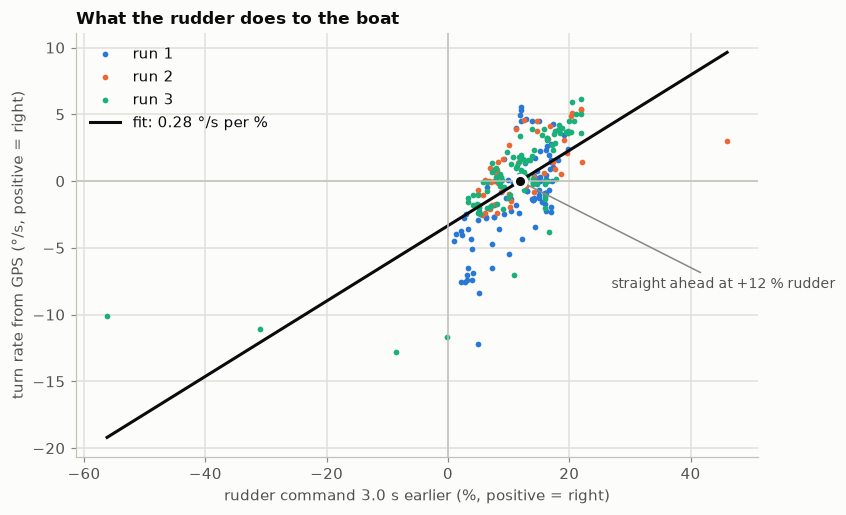

,steering loop
rudder effectiveness (°/s of turn per % rudder),0.28
rudder for straight ahead (%),11.8
steering response time (s): error shrinks by ~63 % in,3.2
delay from rudder to turn (s),3.0
"phase margin (°, 45-60 is comfortable, 0 weaves)",36
gain could rise by (x) before weaving starts,1.7
rudder range the fit is based on (%),"-56 to +46, most samples +3 to +20"


In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
used = []
for n in runs.index:
    r = resp[resp.run == n]
    rud = np.interp(r.unix - LAG_S, r.unix, r.rudder, left=np.nan)
    ok = (r.speed >= MIN_SPEED_M_S).to_numpy() & ~np.isnan(rud)
    ax.scatter(rud[ok], r.turn_rate.to_numpy()[ok], s=14, color=RUN_COLORS[n], linewidths=0, label="run %d" % n)
    used.append(rud[ok])
used = np.concatenate(used)
grid = np.array([used.min(), used.max()])  # the fit only where there is data
ax.plot(grid, K * grid + B, color=INK, lw=2, label="fit: %.2f °/s per %%" % K)
ax.axhline(0, color=AXIS, lw=1)
ax.axvline(0, color=AXIS, lw=1)
straight = -B / K
ax.plot([straight], [0], "o", color=INK, ms=8, mec=SURFACE, mew=2, zorder=5)
ax.annotate("straight ahead at %+.0f %% rudder" % straight, (straight, 0), xytext=(60, -70), textcoords="offset points",
            ha="left", color=INK_2, fontsize=9, arrowprops=dict(arrowstyle="-", color=MUTED, lw=1))
ax.set_xlabel("rudder command %.1f s earlier (%%, positive = right)" % LAG_S)
ax.set_ylabel("turn rate from GPS (°/s, positive = right)")
ax.set_title("What the rudder does to the boat")
ax.legend(loc="upper left")
plt.show()

loop = K * GAIN_PCT_PER_DEG  # 1/s: how fast the course error shrinks, per second
tau = 1 / loop
margin_deg = 90 - np.degrees(loop * LAG_S)
gain_to_weave = (np.pi / 2) / (loop * LAG_S)
pd.Series({
    "rudder effectiveness (°/s of turn per % rudder)": round(K, 2),
    "rudder for straight ahead (%)": round(straight, 1),
    "steering response time (s): error shrinks by ~63 % in": round(tau, 1),
    "delay from rudder to turn (s)": LAG_S,
    "phase margin (°, 45-60 is comfortable, 0 weaves)": round(margin_deg),
    "gain could rise by (x) before weaving starts": round(gain_to_weave, 1),
    "rudder range the fit is based on (%)": "%+.0f to %+.0f, most samples %+.0f to %+.0f" % (
        used.min(), used.max(), np.percentile(used, 5), np.percentile(used, 95)),
}, name="steering loop").to_frame()

### Rudder sensitivity: findings

- **No weaving.** The controller's course error never swung back and forth: once on course it
  stayed on one side, and the rudder did not reverse while holding a course. Run 3's single zero
  crossing is not a swing: it started 83° off to one side and settled about 11° off to the other,
  because of the trim offset below.
- **It gets on course quickly.** Within 15° of the wanted course in a few seconds for the 60–80°
  initial errors of runs 2 and 3; run 1, starting about 160° off and from rest, took longer.
- **The loop sits in a reasonable place.** With the boat's measured rudder effectiveness and the
  delay of about two to three seconds between a rudder command and the boat turning (rudder, hull
  and GPS together), the controller's gain gives a response time of a few seconds and a phase
  margin of a few tens of degrees. The gain could rise somewhat before weaving starts, but not by
  a large factor: this is a sensible setting, not an over-damped one.
- **The steady error is the rudder trim, not the gain.** At zero rudder the boat turns left by a
  few degrees a second; straight ahead needs a positive rudder of about the size the transmitter
  is trimmed to. A proportional controller only produces that rudder by holding an error, which is
  the steady 9–12° offset seen in every run. Raising the gain would shrink that error but eat the
  margin; setting the autopilot's neutral to the straight-ahead rudder removes it.

**Two caveats, and one consequence.**

- The course error is measured by the compass, which in this test moved only about a third as far
  as the boat in runs 2 and 3. So the controller saw less of each turn than really happened,
  which makes it *less* aggressive than its gain suggests.
- **Once the compass is fixed (or replaced by a gyro and GPS heading), the effective loop gain
  goes up**, possibly by close to the factor the compass was under-reading. With the margin found
  here, that could be enough to start weaving: re-check the rudder gain after the heading source
  changes, before going far from shore.
- The rudder effectiveness comes mostly from small rudder angles (about 0–25 %): the big rudder
  moments were at the start of each run, when the boat was still too slow for a usable GPS
  course. Large rudder may turn the boat less than proportionally.
- Rudder effectiveness grows with speed (roughly with its square). These runs were all at about
  0.8 m/s; at higher throttle the same gain is more sensitive.